In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nAvailable Files and Folders:")
print(os.listdir())

Current Working Directory:
C:\Users\KESHAV DEV GAUR\OneDrive\Desktop\EconoCausal\notebooks

Available Files and Folders:
['.ipynb_checkpoints', '01_data_inspection.ipynb', '02_data_quality_analysis.ipynb', '03_dataset_relationships.ipynb', '04_target_analysis.ipynb', '05_customer_coupon_analysis.ipynb', '06_transaction_discount_analysis.ipynb', '07_dataset_integration.ipynb', '08_treatment_outcome_analysis.ipynb', '09_campaign_exposure_analysis.ipynb', '10_customer_campaign_relationships.ipynb', '11_treatment_outcome_definition.ipynb', '12_treatment_assignment_analysis.ipynb', '13_customer_exposure_analysis.ipynb', '14_causal_identification_feasibility.ipynb', '15_treatment_assignment_evidence.ipynb', '16_dataset_documentation_causal_design.ipynb', '17_treatment_definition_identification_strategy.ipynb', '18_dataset_documentation_research.ipynb', '19_transaction_outcome_validation.ipynb', '20_transaction_measurement_outcome_feasibility.ipynb', 'Untitled.ipynb']


In [7]:
import os

print("Checking dataset paths:\n")

paths = [
    "../data/raw/customer_transactions.csv",
    "../../data/raw/customer_transactions.csv",
    "data/raw/customer_transactions.csv"
]

for path in paths:
    print(path, "->", os.path.exists(path))

Checking dataset paths:

../data/raw/customer_transactions.csv -> False
../../data/raw/customer_transactions.csv -> False
data/raw/customer_transactions.csv -> False


In [8]:
import os

print("Searching for customer_transactions.csv...")

search_root = os.path.dirname(os.getcwd())

for root, dirs, files in os.walk(search_root):
    if "customer_transactions.csv" in files:
        print("FOUND!")
        print("Full path:", os.path.join(root, "customer_transactions.csv"))

Searching for customer_transactions.csv...


In [9]:
import os

search_root = os.path.join(
    os.path.expanduser("~"),
    "OneDrive",
    "Desktop"
)

target = "customer_transactions.csv"

found = False

for root, dirs, files in os.walk(search_root):
    if target in files:
        print("FOUND:", os.path.join(root, target))
        found = True
        break

if not found:
    print("File not found in Desktop.")

File not found in Desktop.


In [10]:
from pathlib import Path

DATA_DIR = Path("../data/raw")

print("Data folder exists:", DATA_DIR.exists())
print("\nCSV files found:")

for file in sorted(DATA_DIR.glob("*.csv")):
    print(file.name)

Data folder exists: True

CSV files found:
campaign_data.csv
coupon_item_mapping.csv
customer_demographics.csv
customer_transaction_data.csv
item_data.csv
sample_submission_Byiv0dS.csv
test_QyjYwdj.csv
train.csv


In [11]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/customer_transaction_data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1324566, 7)


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0
3,2012-01-02,1501,33647,1,67.32,0.00,0.0
4,2012-01-02,1501,48199,1,71.24,-28.14,0.0


In [12]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Columns:
['date', 'customer_id', 'item_id', 'quantity', 'selling_price', 'other_discount', 'coupon_discount']

Data Types:
date                   str
customer_id          int64
item_id              int64
quantity             int64
selling_price      float64
other_discount     float64
coupon_discount    float64
dtype: object

Missing Values:
date               0
customer_id        0
item_id            0
quantity           0
selling_price      0
other_discount     0
coupon_discount    0
dtype: int64

Duplicate Records: 2916


In [13]:
print("AVAILABLE DATASET FEATURES")
print("=" * 60)

for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

print("\nNUMERICAL SUMMARY")
display(df.describe(include="all").T)

AVAILABLE DATASET FEATURES
1. date
2. customer_id
3. item_id
4. quantity
5. selling_price
6. other_discount
7. coupon_discount

NUMERICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,1324566,549,2012-09-03,4753,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,1324566.0,NaN,NaN,NaN,804.001972,457.336313,1.0,418.0,801.0,1198.0,1582.0
item_id,1324566.0,NaN,NaN,NaN,29519.03016,17908.064406,1.0,14684.0,26597.0,42405.75,74066.0
quantity,1324566.0,NaN,NaN,NaN,130.66334,1311.545447,1.0,1.0,1.0,1.0,89638.0
selling_price,1324566.0,NaN,NaN,NaN,114.603633,152.905303,0.36,49.16,78.01,124.31,17809.64
other_discount,1324566.0,NaN,NaN,NaN,-17.768707,37.888674,-3120.31,-23.15,-1.78,0.0,0.0
coupon_discount,1324566.0,NaN,NaN,NaN,-0.594898,7.069367,-1992.23,0.0,0.0,0.0,0.0


In [14]:
print("Potential Treatment Variables:")

for col in df.columns:
    if any(word in col.lower() for word in
           ['coupon', 'discount', 'campaign', 'offer', 'promo']):
        print("-", col)

print("\nPotential Outcome Variables:")

for col in df.columns:
    if any(word in col.lower() for word in
           ['amount', 'sales', 'quantity', 'purchase', 'revenue', 'spend']):
        print("-", col)

Potential Treatment Variables:
- other_discount
- coupon_discount

Potential Outcome Variables:
- quantity


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
campaign_df = pd.read_csv("../data/raw/campaign_data.csv")

coupon_df = pd.read_csv("../data/raw/coupon_item_mapping.csv")

customer_df = pd.read_csv("../data/raw/customer_demographics.csv")

transaction_df = pd.read_csv("../data/raw/customer_transaction_data.csv")

item_df = pd.read_csv("../data/raw/item_data.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [17]:
datasets = {
    "Campaign": campaign_df,
    "Coupon Mapping": coupon_df,
    "Customer": customer_df,
    "Transaction": transaction_df,
    "Item": item_df
}

for name, data in datasets.items():

    print("\n", "=" * 60)
    print(name.upper())
    print("=" * 60)

    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())

    display(data.head(3))


CAMPAIGN
Shape: (28, 4)
Columns: ['campaign_id', 'campaign_type', 'start_date', 'end_date']


,campaign_id,campaign_type,start_date,end_date
0,24,Y,21/10/13,20/12/13
1,25,Y,21/10/13,22/11/13
2,20,Y,07/09/13,16/11/13



COUPON MAPPING
Shape: (92663, 2)
Columns: ['coupon_id', 'item_id']


,coupon_id,item_id
0,105,37
1,107,75
2,494,76



CUSTOMER
Shape: (760, 7)
Columns: ['customer_id', 'age_range', 'marital_status', 'rented', 'family_size', 'no_of_children', 'income_bracket']


,customer_id,age_range,marital_status,rented,family_size,no_of_children,income_bracket
0,1,70+,Married,0,2,NaN,4
1,6,46-55,Married,0,2,NaN,5
2,7,26-35,NaN,0,3,1,3



TRANSACTION
Shape: (1324566, 7)
Columns: ['date', 'customer_id', 'item_id', 'quantity', 'selling_price', 'other_discount', 'coupon_discount']


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0



ITEM
Shape: (74066, 4)
Columns: ['item_id', 'brand', 'brand_type', 'category']


,item_id,brand,brand_type,category
0,1,1,Established,Grocery
1,2,1,Established,Miscellaneous
2,3,56,Local,Bakery


In [18]:
keywords = [
    'coupon',
    'campaign',
    'discount',
    'offer',
    'promotion',
    'redeem',
    'exposure'
]

print("POTENTIAL TREATMENT VARIABLES")

for name, data in datasets.items():

    for col in data.columns:

        if any(word in col.lower() for word in keywords):

            print(f"{name}: {col}")

POTENTIAL TREATMENT VARIABLES
Campaign: campaign_id
Campaign: campaign_type
Coupon Mapping: coupon_id
Transaction: other_discount
Transaction: coupon_discount


In [19]:
for name, data in datasets.items():

    for col in data.columns:

        if any(word in col.lower() for word in keywords):

            print("\nDataset:", name)
            print("Variable:", col)

            print("\nUnique Values:")
            print(data[col].nunique())

            print("\nMissing Values:")
            print(data[col].isnull().sum())

            print("\nValue Distribution:")
            display(data[col].value_counts().head(10))


Dataset: Campaign
Variable: campaign_id

Unique Values:
28

Missing Values:
0

Value Distribution:


campaign_id
24    1
25    1
20    1
23    1
21    1
22    1
18    1
19    1
17    1
16    1
Name: count, dtype: int64


Dataset: Campaign
Variable: campaign_type

Unique Values:
2

Missing Values:
0

Value Distribution:


campaign_type
Y    22
X     6
Name: count, dtype: int64


Dataset: Coupon Mapping
Variable: coupon_id

Unique Values:
1116

Missing Values:
0

Value Distribution:


coupon_id
32    11814
23    11813
22     4947
31     4873
24     4394
33     4394
8      3718
6      3713
29     3385
20     3372
Name: count, dtype: int64


Dataset: Transaction
Variable: other_discount

Unique Values:
1418

Missing Values:
0

Value Distribution:


other_discount
 0.00     652917
-17.45     34518
-7.12      27045
-35.62     21484
-35.26     20737
-10.33     20656
-10.69     20404
-14.25     18871
-17.81     17931
-3.56      17605
Name: count, dtype: int64


Dataset: Transaction
Variable: coupon_discount

Unique Values:
232

Missing Values:
0

Value Distribution:


coupon_discount
 0.00     1303280
-35.62       6038
-17.81       3605
-19.59       1808
-26.71       1724
-12.47       1062
-14.25       1024
-89.05        986
-8.90         792
-71.24        788
Name: count, dtype: int64

In [20]:
treatment_candidates = []

for name, data in datasets.items():

    for col in data.columns:

        if any(word in col.lower() for word in keywords):

            treatment_candidates.append({
                "Dataset": name,
                "Variable": col,
                "Missing Values": data[col].isnull().sum(),
                "Unique Values": data[col].nunique()
            })

treatment_summary = pd.DataFrame(treatment_candidates)

display(treatment_summary)

,Dataset,Variable,Missing Values,Unique Values
0,Campaign,campaign_id,0,28
1,Campaign,campaign_type,0,2
2,Coupon Mapping,coupon_id,0,1116
3,Transaction,other_discount,0,1418
4,Transaction,coupon_discount,0,232


In [21]:
print("TREATMENT ASSIGNMENT ANALYSIS")
print("=" * 60)

print("\nCampaign Dataset:")
display(campaign_df.head())

print("\nCoupon Mapping Dataset:")
display(coupon_df.head())

print("\nTransaction Dataset:")
display(transaction_df.head())

TREATMENT ASSIGNMENT ANALYSIS

Campaign Dataset:


,campaign_id,campaign_type,start_date,end_date
0,24,Y,21/10/13,20/12/13
1,25,Y,21/10/13,22/11/13
2,20,Y,07/09/13,16/11/13
3,23,Y,08/10/13,15/11/13
4,21,Y,16/09/13,18/10/13



Coupon Mapping Dataset:


,coupon_id,item_id
0,105,37
1,107,75
2,494,76
3,522,77
4,518,77



Transaction Dataset:


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0
3,2012-01-02,1501,33647,1,67.32,0.00,0.0
4,2012-01-02,1501,48199,1,71.24,-28.14,0.0


In [22]:
print("Campaign-Coupon Relationship")

print("Campaign records:", len(campaign_df))
print("Unique campaigns:", campaign_df.nunique())

print("\nCoupon Mapping Records:", len(coupon_df))
print("Unique coupon IDs:",
      coupon_df['coupon_id'].nunique()
      if 'coupon_id' in coupon_df.columns else "Column unavailable")

Campaign-Coupon Relationship
Campaign records: 28
Unique campaigns: campaign_id      28
campaign_type     2
start_date       25
end_date         26
dtype: int64

Coupon Mapping Records: 92663
Unique coupon IDs: 1116


In [23]:
train_df = pd.read_csv("../data/raw/train.csv")

print("Training Dataset Shape:", train_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nRedemption Distribution:")

if 'redemption_status' in train_df.columns:
    display(train_df['redemption_status'].value_counts())

    print("\nRedemption Percentage:")
    display(train_df['redemption_status'].value_counts(normalize=True) * 100)

Training Dataset Shape: (78369, 5)

Columns:
['id', 'campaign_id', 'coupon_id', 'customer_id', 'redemption_status']

Redemption Distribution:


redemption_status
0    77640
1      729
Name: count, dtype: int64


Redemption Percentage:


redemption_status
0    99.069785
1     0.930215
Name: proportion, dtype: float64

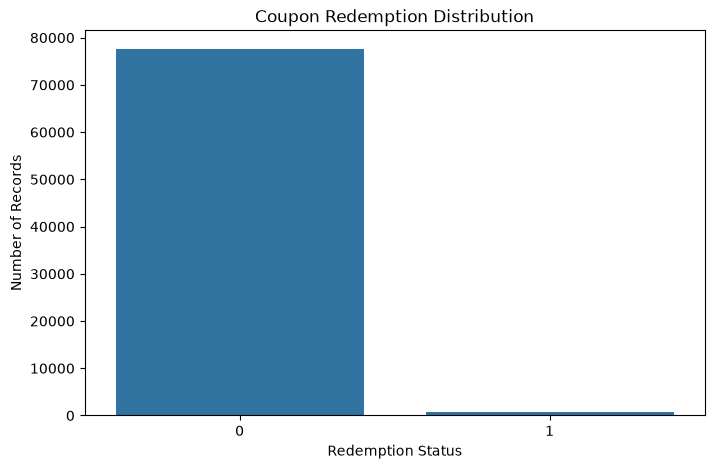

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'redemption_status' in train_df.columns:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=train_df,
        x='redemption_status'
    )

    plt.title("Coupon Redemption Distribution")
    plt.xlabel("Redemption Status")
    plt.ylabel("Number of Records")

    plt.show()

In [25]:
if 'redemption_status' in train_df.columns:

    total = len(train_df)

    redeemed = (train_df['redemption_status'] == 1).sum()

    not_redeemed = (train_df['redemption_status'] == 0).sum()

    print("TREATMENT STATISTICS")
    print("=" * 40)

    print("Total Records:", total)
    print("Redeemed:", redeemed)
    print("Not Redeemed:", not_redeemed)

    print("Redemption Rate:",
          round((redeemed / total) * 100, 2), "%")

TREATMENT STATISTICS
Total Records: 78369
Redeemed: 729
Not Redeemed: 77640
Redemption Rate: 0.93 %


In [26]:
treatment_assessment = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Redeemed Records",
        "Non-Redeemed Records",
        "Redemption Rate (%)"
    ],
    "Value": [
        total,
        redeemed,
        not_redeemed,
        round((redeemed / total) * 100, 2)
    ]
})

display(treatment_assessment)

,Metric,Value
0,Total Records,78369.00
1,Redeemed Records,729.00
2,Non-Redeemed Records,77640.00
3,Redemption Rate (%),0.93


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
transaction_df = pd.read_csv(
    "../data/raw/customer_transaction_data.csv"
)

train_df = pd.read_csv("../data/raw/train.csv")

customer_df = pd.read_csv(
    "../data/raw/customer_demographics.csv"
)

print("Datasets loaded successfully!")

print("Transaction Shape:", transaction_df.shape)
print("Training Shape:", train_df.shape)
print("Customer Shape:", customer_df.shape)

Datasets loaded successfully!
Transaction Shape: (1324566, 7)
Training Shape: (78369, 5)
Customer Shape: (760, 7)


In [29]:
print("TRANSACTION DATASET")
print("=" * 50)

print("Columns:", transaction_df.columns.tolist())

display(transaction_df.head())

print("\nData Types:")
print(transaction_df.dtypes)

print("\nMissing Values:")
print(transaction_df.isnull().sum())

TRANSACTION DATASET
Columns: ['date', 'customer_id', 'item_id', 'quantity', 'selling_price', 'other_discount', 'coupon_discount']


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0
3,2012-01-02,1501,33647,1,67.32,0.00,0.0
4,2012-01-02,1501,48199,1,71.24,-28.14,0.0



Data Types:
date                   str
customer_id          int64
item_id              int64
quantity             int64
selling_price      float64
other_discount     float64
coupon_discount    float64
dtype: object

Missing Values:
date               0
customer_id        0
item_id            0
quantity           0
selling_price      0
other_discount     0
coupon_discount    0
dtype: int64


In [30]:
outcome_keywords = [
    'amount',
    'sales',
    'quantity',
    'purchase',
    'revenue',
    'spend',
    'transaction',
    'price'
]

print("POTENTIAL OUTCOME VARIABLES")

for col in transaction_df.columns:
    if any(word in col.lower() for word in outcome_keywords):
        print("-", col)

POTENTIAL OUTCOME VARIABLES
- quantity
- selling_price


In [31]:
display(
    transaction_df.describe(include='all').T
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,1324566,549,2012-09-03,4753,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,1324566.0,NaN,NaN,NaN,804.001972,457.336313,1.0,418.0,801.0,1198.0,1582.0
item_id,1324566.0,NaN,NaN,NaN,29519.03016,17908.064406,1.0,14684.0,26597.0,42405.75,74066.0
quantity,1324566.0,NaN,NaN,NaN,130.66334,1311.545447,1.0,1.0,1.0,1.0,89638.0
selling_price,1324566.0,NaN,NaN,NaN,114.603633,152.905303,0.36,49.16,78.01,124.31,17809.64
other_discount,1324566.0,NaN,NaN,NaN,-17.768707,37.888674,-3120.31,-23.15,-1.78,0.0,0.0
coupon_discount,1324566.0,NaN,NaN,NaN,-0.594898,7.069367,-1992.23,0.0,0.0,0.0,0.0


In [32]:
customer_candidates = [
    col for col in transaction_df.columns
    if 'customer' in col.lower()
]

print("Customer-related columns:", customer_candidates)

Customer-related columns: ['customer_id']


In [33]:
if 'customer_id' in transaction_df.columns:

    customer_activity = (
        transaction_df.groupby('customer_id')
        .size()
        .reset_index(name='transaction_count')
    )

    print("Unique Customers:", len(customer_activity))

    display(customer_activity.head())

    print("\nTransaction Count Summary:")
    print(customer_activity['transaction_count'].describe())

Unique Customers: 1582


,customer_id,transaction_count
0,1,1048
1,2,419
2,3,705
3,4,220
4,5,792



Transaction Count Summary:
count    1582.000000
mean      837.273072
std       604.525972
min        79.000000
25%       416.000000
50%       664.000000
75%      1078.500000
max      4522.000000
Name: transaction_count, dtype: float64


In [34]:
customer_outcomes = (
    transaction_df.groupby('customer_id')
    .agg(
        total_transactions=('customer_id', 'count'),
        total_items=('item_id', 'count'),
        unique_items=('item_id', 'nunique')
    )
    .reset_index()
)

print("Customer-Level Outcome Analysis")
print("Total Customers:", len(customer_outcomes))

display(customer_outcomes.head())

Customer-Level Outcome Analysis
Total Customers: 1582


,customer_id,total_transactions,total_items,unique_items
0,1,1048,1048,463
1,2,419,419,352
2,3,705,705,406
3,4,220,220,125
4,5,792,792,490


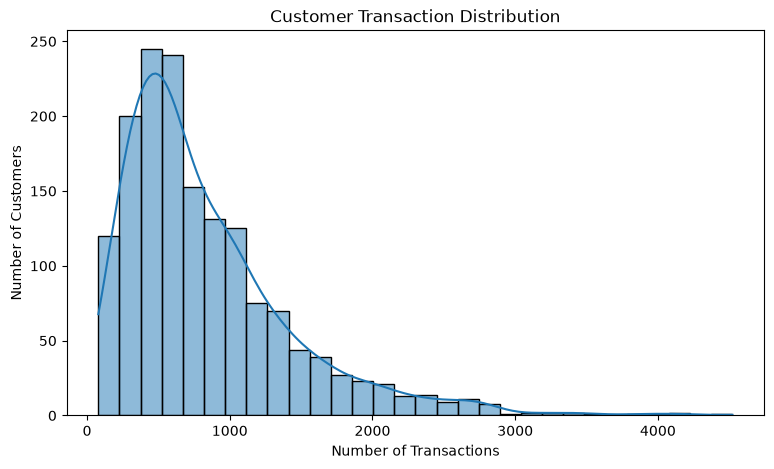

In [35]:
plt.figure(figsize=(9, 5))

sns.histplot(
    customer_outcomes['total_transactions'],
    bins=30,
    kde=True
)

plt.title("Customer Transaction Distribution")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.show()

In [36]:
display(
    customer_outcomes[
        ['total_transactions', 'total_items', 'unique_items']
    ].describe()
)

,total_transactions,total_items,unique_items
count,1582.000000,1582.000000,1582.000000
mean,837.273072,837.273072,497.905815
std,604.525972,604.525972,300.306322
min,79.000000,79.000000,47.000000
25%,416.000000,416.000000,284.000000
50%,664.000000,664.000000,432.000000
75%,1078.500000,1078.500000,644.750000
max,4522.000000,4522.000000,2432.000000


In [37]:
import os

os.makedirs("../data/processed", exist_ok=True)

customer_outcomes.to_csv(
    "../data/processed/customer_level_outcomes.csv",
    index=False
)

print("Customer-level outcomes saved successfully!")

Customer-level outcomes saved successfully!


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [39]:
customer_df = pd.read_csv(
    "../data/raw/customer_demographics.csv"
)

transaction_df = pd.read_csv(
    "../data/raw/customer_transaction_data.csv"
)

train_df = pd.read_csv("../data/raw/train.csv")

outcomes_df = pd.read_csv(
    "../data/processed/customer_level_outcomes.csv"
)

print("All datasets loaded successfully!")

print("Customer:", customer_df.shape)
print("Transactions:", transaction_df.shape)
print("Training:", train_df.shape)
print("Outcomes:", outcomes_df.shape)

All datasets loaded successfully!
Customer: (760, 7)
Transactions: (1324566, 7)
Training: (78369, 5)
Outcomes: (1582, 4)


In [40]:
print("CUSTOMER DEMOGRAPHICS")
print("=" * 50)

print(customer_df.columns.tolist())

display(customer_df.head())

print("\nData Types:")
print(customer_df.dtypes)

print("\nMissing Values:")
print(customer_df.isnull().sum())

CUSTOMER DEMOGRAPHICS
['customer_id', 'age_range', 'marital_status', 'rented', 'family_size', 'no_of_children', 'income_bracket']


,customer_id,age_range,marital_status,rented,family_size,no_of_children,income_bracket
0,1,70+,Married,0,2,NaN,4
1,6,46-55,Married,0,2,NaN,5
2,7,26-35,NaN,0,3,1,3
3,8,26-35,NaN,0,4,2,6
4,10,46-55,Single,0,1,NaN,5



Data Types:
customer_id       int64
age_range           str
marital_status      str
rented            int64
family_size         str
no_of_children      str
income_bracket    int64
dtype: object

Missing Values:
customer_id         0
age_range           0
marital_status    329
rented              0
family_size         0
no_of_children    538
income_bracket      0
dtype: int64


In [41]:
analysis_df = outcomes_df.merge(
    customer_df,
    on='customer_id',
    how='left'
)

print("Merged Dataset Shape:", analysis_df.shape)

display(analysis_df.head())

Merged Dataset Shape: (1582, 10)


,customer_id,total_transactions,total_items,unique_items,age_range,marital_status,rented,family_size,no_of_children,income_bracket
0,1,1048,1048,463,70+,Married,0.0,2,NaN,4.0
1,2,419,419,352,NaN,NaN,NaN,NaN,NaN,NaN
2,3,705,705,406,NaN,NaN,NaN,NaN,NaN,NaN
3,4,220,220,125,NaN,NaN,NaN,NaN,NaN,NaN
4,5,792,792,490,NaN,NaN,NaN,NaN,NaN,NaN


In [42]:
print("Potential Confounding Variables")
print("=" * 50)

for col in analysis_df.columns:

    if col not in [
        'customer_id',
        'total_transactions',
        'total_items',
        'unique_items'
    ]:

        print(
            col,
            "| Unique Values:", analysis_df[col].nunique(),
            "| Missing:", analysis_df[col].isnull().sum()
        )

Potential Confounding Variables
age_range | Unique Values: 6 | Missing: 822
marital_status | Unique Values: 2 | Missing: 1151
rented | Unique Values: 2 | Missing: 822
family_size | Unique Values: 5 | Missing: 822
no_of_children | Unique Values: 3 | Missing: 1360
income_bracket | Unique Values: 12 | Missing: 822


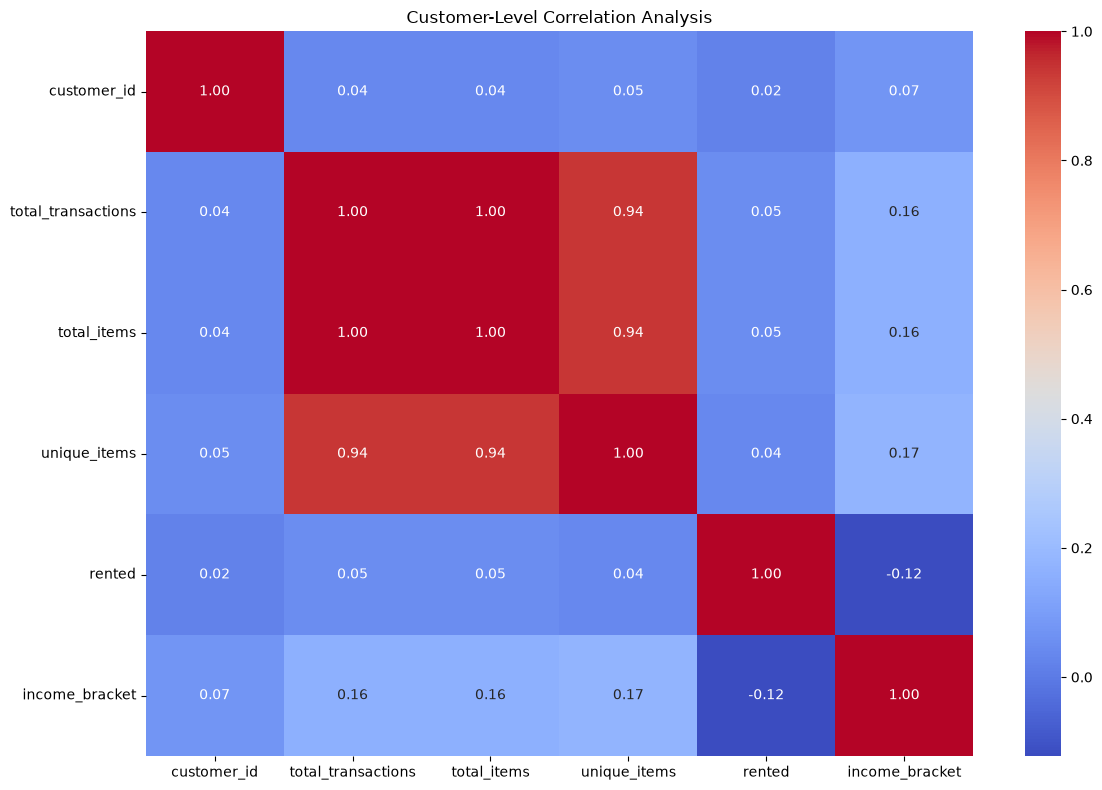

In [43]:
numeric_df = analysis_df.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Customer-Level Correlation Analysis")
plt.tight_layout()
plt.show()

In [44]:
analysis_df.to_csv(
    "../data/processed/confounding_analysis_data.csv",
    index=False
)

print("Confounding analysis dataset saved successfully!")

Confounding analysis dataset saved successfully!


In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [46]:
customer_df = pd.read_csv(
    "../data/raw/customer_demographics.csv"
)

transaction_df = pd.read_csv(
    "../data/raw/customer_transaction_data.csv"
)

train_df = pd.read_csv(
    "../data/raw/train.csv"
)

outcomes_df = pd.read_csv(
    "../data/processed/customer_level_outcomes.csv"
)

confounding_df = pd.read_csv(
    "../data/processed/confounding_analysis_data.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [47]:
datasets = {
    "Customer Demographics": customer_df,
    "Transactions": transaction_df,
    "Training Data": train_df,
    "Customer Outcomes": outcomes_df,
    "Confounding Analysis": confounding_df
}

assessment = []

for name, data in datasets.items():

    assessment.append({
        "Dataset": name,
        "Rows": data.shape[0],
        "Columns": data.shape[1],
        "Missing Values": data.isnull().sum().sum(),
        "Duplicate Rows": data.duplicated().sum()
    })

assessment_df = pd.DataFrame(assessment)

display(assessment_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Customer Demographics,760,7,867,0
1,Transactions,1324566,7,0,2916
2,Training Data,78369,5,0,0
3,Customer Outcomes,1582,4,0,0
4,Confounding Analysis,1582,10,5799,0


In [48]:
treatment_keywords = [
    'coupon',
    'campaign',
    'discount',
    'offer',
    'promotion',
    'exposure',
    'treatment'
]

treatment_features = []

for name, data in datasets.items():

    for col in data.columns:

        if any(word in col.lower() for word in treatment_keywords):

            treatment_features.append({
                "Dataset": name,
                "Variable": col,
                "Unique Values": data[col].nunique(),
                "Missing Values": data[col].isnull().sum()
            })

treatment_df = pd.DataFrame(treatment_features)

display(treatment_df)

,Dataset,Variable,Unique Values,Missing Values
0,Transactions,other_discount,1418,0
1,Transactions,coupon_discount,232,0
2,Training Data,campaign_id,18,0
3,Training Data,coupon_id,866,0


In [49]:
outcome_keywords = [
    'amount',
    'sales',
    'revenue',
    'spend',
    'purchase',
    'transaction',
    'quantity'
]

outcome_features = []

for name, data in datasets.items():

    for col in data.columns:

        if any(word in col.lower() for word in outcome_keywords):

            outcome_features.append({
                "Dataset": name,
                "Variable": col,
                "Unique Values": data[col].nunique(),
                "Missing Values": data[col].isnull().sum()
            })

outcome_df = pd.DataFrame(outcome_features)

display(outcome_df)

,Dataset,Variable,Unique Values,Missing Values
0,Transactions,quantity,9252,0
1,Customer Outcomes,total_transactions,1009,0
2,Confounding Analysis,total_transactions,1009,0


In [50]:
print("=" * 60)
print("ECONOCAUSAL - FINAL CAUSAL FEASIBILITY ASSESSMENT")
print("=" * 60)

print("\n1. Dataset Availability")
print("Status: Assessed")

print("\n2. Customer-Level Outcome Measurement")
print("Status: Aggregated transaction counts and item activity")

print("\n3. Treatment Assignment")
print("Status: Requires verification")

print("\n4. Confounding Variables")
print("Status: Potential candidates identified")

print("\n5. Causal Identification")
print("Status: Requires further validation")

print("\n6. Double Machine Learning")
print("Status: Deferred until identification assumptions are validated")

ECONOCAUSAL - FINAL CAUSAL FEASIBILITY ASSESSMENT

1. Dataset Availability
Status: Assessed

2. Customer-Level Outcome Measurement
Status: Aggregated transaction counts and item activity

3. Treatment Assignment
Status: Requires verification

4. Confounding Variables
Status: Potential candidates identified

5. Causal Identification
Status: Requires further validation

6. Double Machine Learning
Status: Deferred until identification assumptions are validated


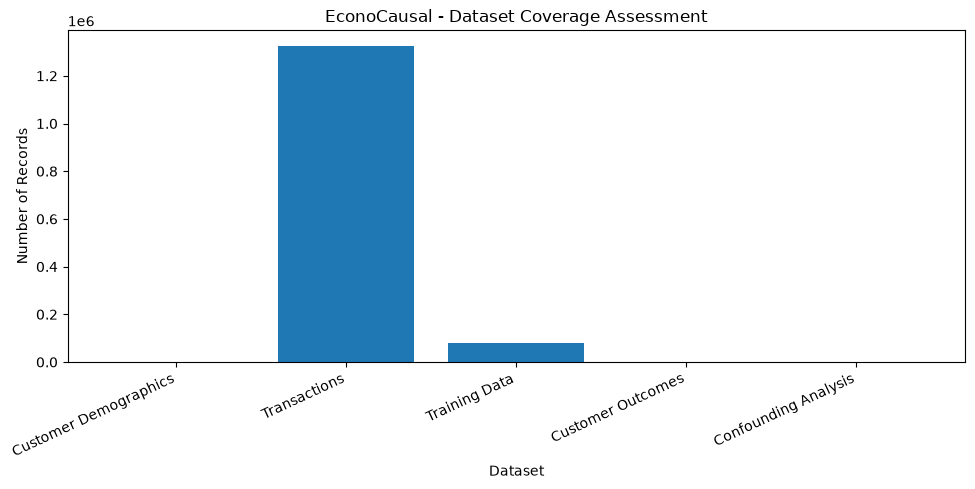

In [51]:
plt.figure(figsize=(10, 5))

plt.bar(
    assessment_df["Dataset"],
    assessment_df["Rows"]
)

plt.title("EconoCausal - Dataset Coverage Assessment")
plt.xlabel("Dataset")
plt.ylabel("Number of Records")

plt.xticks(rotation=25, ha='right')
plt.tight_layout()

plt.show()

In [52]:
os.makedirs("../data/processed", exist_ok=True)

assessment_df.to_csv(
    "../data/processed/final_dataset_assessment.csv",
    index=False
)

treatment_df.to_csv(
    "../data/processed/final_treatment_assessment.csv",
    index=False
)

outcome_df.to_csv(
    "../data/processed/final_outcome_assessment.csv",
    index=False
)

print("Final assessment files saved successfully!")

Final assessment files saved successfully!


In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [54]:
train_df = pd.read_csv("../data/raw/train.csv")

print("Training dataset loaded successfully!")
print("Shape:", train_df.shape)

display(train_df.head())

Training dataset loaded successfully!
Shape: (78369, 5)


,id,campaign_id,coupon_id,customer_id,redemption_status
0,1,13,27,1053,0
1,2,13,116,48,0
2,6,9,635,205,0
3,7,13,644,1050,0
4,9,8,1017,1489,0


In [55]:
print("Dataset Information")
print("=" * 50)

print("Shape:", train_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nData Types:")
print(train_df.dtypes)

print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nDuplicate Records:", train_df.duplicated().sum())

Dataset Information
Shape: (78369, 5)

Columns:
['id', 'campaign_id', 'coupon_id', 'customer_id', 'redemption_status']

Data Types:
id                   int64
campaign_id          int64
coupon_id            int64
customer_id          int64
redemption_status    int64
dtype: object

Missing Values:
id                   0
campaign_id          0
coupon_id            0
customer_id          0
redemption_status    0
dtype: int64

Duplicate Records: 0


In [56]:
target = 'redemption_status'

if target in train_df.columns:

    print("Target variable found!")

    print("\nTarget Distribution:")
    display(train_df[target].value_counts())

    print("\nTarget Percentage:")
    display(train_df[target].value_counts(normalize=True) * 100)

else:
    print("Target variable not found. Check dataset columns.")

Target variable found!

Target Distribution:


redemption_status
0    77640
1      729
Name: count, dtype: int64


Target Percentage:


redemption_status
0    99.069785
1     0.930215
Name: proportion, dtype: float64

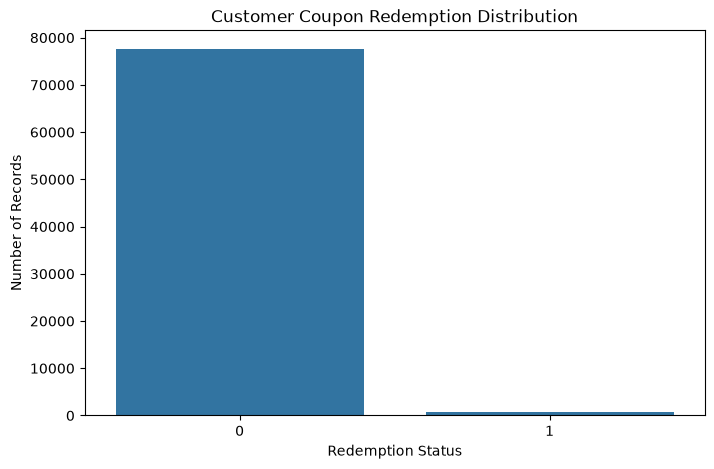

In [57]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x='redemption_status'
)

plt.title("Customer Coupon Redemption Distribution")
plt.xlabel("Redemption Status")
plt.ylabel("Number of Records")

plt.show()

In [58]:
import os

os.makedirs("../data/processed", exist_ok=True)

train_df.to_csv(
    "../data/processed/ml_training_dataset.csv",
    index=False
)

print("ML training dataset saved successfully!")

ML training dataset saved successfully!


In [59]:
campaign_df = pd.read_csv("../data/raw/campaign_data.csv")

coupon_df = pd.read_csv("../data/raw/coupon_item_mapping.csv")

customer_df = pd.read_csv("../data/raw/customer_demographics.csv")

transaction_df = pd.read_csv("../data/raw/customer_transaction_data.csv")

item_df = pd.read_csv("../data/raw/item_data.csv")

print("All supporting datasets loaded!")


All supporting datasets loaded!


In [60]:
datasets = {
    "Campaign": campaign_df,
    "Coupon Mapping": coupon_df,
    "Customer Demographics": customer_df,
    "Transactions": transaction_df,
    "Item": item_df
}

for name, data in datasets.items():

    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())

    display(data.head(3))


CAMPAIGN
Shape: (28, 4)
Columns: ['campaign_id', 'campaign_type', 'start_date', 'end_date']


,campaign_id,campaign_type,start_date,end_date
0,24,Y,21/10/13,20/12/13
1,25,Y,21/10/13,22/11/13
2,20,Y,07/09/13,16/11/13



COUPON MAPPING
Shape: (92663, 2)
Columns: ['coupon_id', 'item_id']


,coupon_id,item_id
0,105,37
1,107,75
2,494,76



CUSTOMER DEMOGRAPHICS
Shape: (760, 7)
Columns: ['customer_id', 'age_range', 'marital_status', 'rented', 'family_size', 'no_of_children', 'income_bracket']


,customer_id,age_range,marital_status,rented,family_size,no_of_children,income_bracket
0,1,70+,Married,0,2,NaN,4
1,6,46-55,Married,0,2,NaN,5
2,7,26-35,NaN,0,3,1,3



TRANSACTIONS
Shape: (1324566, 7)
Columns: ['date', 'customer_id', 'item_id', 'quantity', 'selling_price', 'other_discount', 'coupon_discount']


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0



ITEM
Shape: (74066, 4)
Columns: ['item_id', 'brand', 'brand_type', 'category']


,item_id,brand,brand_type,category
0,1,1,Established,Grocery
1,2,1,Established,Miscellaneous
2,3,56,Local,Bakery


In [61]:
print("TRAINING DATA")
print(train_df.columns.tolist())

print("\nCAMPAIGN DATA")
print(campaign_df.columns.tolist())

print("\nCOUPON MAPPING")
print(coupon_df.columns.tolist())

print("\nCUSTOMER DATA")
print(customer_df.columns.tolist())

print("\nTRANSACTION DATA")
print(transaction_df.columns.tolist())

print("\nITEM DATA")
print(item_df.columns.tolist())

TRAINING DATA
['id', 'campaign_id', 'coupon_id', 'customer_id', 'redemption_status']

CAMPAIGN DATA
['campaign_id', 'campaign_type', 'start_date', 'end_date']

COUPON MAPPING
['coupon_id', 'item_id']

CUSTOMER DATA
['customer_id', 'age_range', 'marital_status', 'rented', 'family_size', 'no_of_children', 'income_bracket']

TRANSACTION DATA
['date', 'customer_id', 'item_id', 'quantity', 'selling_price', 'other_discount', 'coupon_discount']

ITEM DATA
['item_id', 'brand', 'brand_type', 'category']


In [62]:
ml_df = train_df.merge(
    campaign_df,
    on='campaign_id',
    how='left'
)

print("After Campaign Merge:", ml_df.shape)
display(ml_df.head())


After Campaign Merge: (78369, 8)


,id,campaign_id,coupon_id,customer_id,redemption_status,campaign_type,start_date,end_date
0,1,13,27,1053,0,X,19/05/13,05/07/13
1,2,13,116,48,0,X,19/05/13,05/07/13
2,6,9,635,205,0,Y,11/03/13,12/04/13
3,7,13,644,1050,0,X,19/05/13,05/07/13
4,9,8,1017,1489,0,X,16/02/13,05/04/13


In [63]:
ml_df = ml_df.merge(
    customer_df,
    on='customer_id',
    how='left'
)

print("After Customer Merge:", ml_df.shape)
display(ml_df.head())

After Customer Merge: (78369, 14)


,id,campaign_id,coupon_id,customer_id,redemption_status,campaign_type,start_date,end_date,age_range,marital_status,rented,family_size,no_of_children,income_bracket
0,1,13,27,1053,0,X,19/05/13,05/07/13,46-55,NaN,0.0,1,NaN,5.0
1,2,13,116,48,0,X,19/05/13,05/07/13,36-45,Married,0.0,2,NaN,3.0
2,6,9,635,205,0,Y,11/03/13,12/04/13,46-55,Married,0.0,2,NaN,7.0
3,7,13,644,1050,0,X,19/05/13,05/07/13,NaN,NaN,NaN,NaN,NaN,NaN
4,9,8,1017,1489,0,X,16/02/13,05/04/13,46-55,Married,0.0,2,NaN,3.0


In [64]:
ml_df = ml_df.merge(
    coupon_df.groupby('coupon_id').agg(
        mapped_item_count=('item_id', 'nunique')
    ).reset_index(),
    on='coupon_id',
    how='left'
)

print("After Coupon Merge:", ml_df.shape)
display(ml_df.head())

After Coupon Merge: (78369, 15)


,id,campaign_id,coupon_id,customer_id,redemption_status,campaign_type,start_date,end_date,age_range,marital_status,rented,family_size,no_of_children,income_bracket,mapped_item_count
0,1,13,27,1053,0,X,19/05/13,05/07/13,46-55,NaN,0.0,1,NaN,5.0,125
1,2,13,116,48,0,X,19/05/13,05/07/13,36-45,Married,0.0,2,NaN,3.0,3
2,6,9,635,205,0,Y,11/03/13,12/04/13,46-55,Married,0.0,2,NaN,7.0,67
3,7,13,644,1050,0,X,19/05/13,05/07/13,NaN,NaN,NaN,NaN,NaN,NaN,4
4,9,8,1017,1489,0,X,16/02/13,05/04/13,46-55,Married,0.0,2,NaN,3.0,32


In [65]:
coupon_items = coupon_df.merge(
    item_df,
    on='item_id',
    how='left'
)

coupon_features = coupon_items.groupby('coupon_id').agg(
    unique_brands=('brand', 'nunique'),
    unique_categories=('category', 'nunique'),
    unique_brand_types=('brand_type', 'nunique')
).reset_index()

ml_df = ml_df.merge(
    coupon_features,
    on='coupon_id',
    how='left'
)

print("Item features merged successfully!")
print("Shape:", ml_df.shape)

display(ml_df.head())

Item features merged successfully!
Shape: (78369, 18)


,id,campaign_id,coupon_id,customer_id,redemption_status,campaign_type,start_date,end_date,age_range,marital_status,rented,family_size,no_of_children,income_bracket,mapped_item_count,unique_brands,unique_categories,unique_brand_types
0,1,13,27,1053,0,X,19/05/13,05/07/13,46-55,NaN,0.0,1,NaN,5.0,125,2,1,1
1,2,13,116,48,0,X,19/05/13,05/07/13,36-45,Married,0.0,2,NaN,3.0,3,1,1,1
2,6,9,635,205,0,Y,11/03/13,12/04/13,46-55,Married,0.0,2,NaN,7.0,67,1,1,1
3,7,13,644,1050,0,X,19/05/13,05/07/13,NaN,NaN,NaN,NaN,NaN,NaN,4,1,1,1
4,9,8,1017,1489,0,X,16/02/13,05/04/13,46-55,Married,0.0,2,NaN,3.0,32,1,1,1


In [66]:
print("FINAL ML DATASET")
print("=" * 50)

print("Shape:", ml_df.shape)

print("\nMissing Values:")
print(ml_df.isnull().sum())

print("\nDuplicate Records:", ml_df.duplicated().sum())

print("\nTarget Distribution:")
print(ml_df['redemption_status'].value_counts())

FINAL ML DATASET
Shape: (78369, 18)

Missing Values:
id                        0
campaign_id               0
coupon_id                 0
customer_id               0
redemption_status         0
campaign_type             0
start_date                0
end_date                  0
age_range             34708
marital_status        52975
rented                34708
family_size           34708
no_of_children        64313
income_bracket        34708
mapped_item_count         0
unique_brands             0
unique_categories         0
unique_brand_types        0
dtype: int64

Duplicate Records: 0

Target Distribution:
redemption_status
0    77640
1      729
Name: count, dtype: int64


In [67]:
print("Campaign Date Information")

display(
    campaign_df[['campaign_id', 'start_date', 'end_date']].head()
)

print("\nTransaction Date Information")

display(
    transaction_df[['date', 'customer_id']].head()
)

print("\nDate Data Types:")
print(campaign_df[['start_date', 'end_date']].dtypes)
print(transaction_df['date'].dtype)

Campaign Date Information


,campaign_id,start_date,end_date
0,24,21/10/13,20/12/13
1,25,21/10/13,22/11/13
2,20,07/09/13,16/11/13
3,23,08/10/13,15/11/13
4,21,16/09/13,18/10/13



Transaction Date Information


,date,customer_id
0,2012-01-02,1501
1,2012-01-02,1501
2,2012-01-02,1501
3,2012-01-02,1501
4,2012-01-02,1501



Date Data Types:
start_date    str
end_date      str
dtype: object
str


In [68]:
# Convert campaign dates
campaign_df['start_date'] = pd.to_datetime(
    campaign_df['start_date'],
    format='%d/%m/%y'
)

campaign_df['end_date'] = pd.to_datetime(
    campaign_df['end_date'],
    format='%d/%m/%y'
)

# Convert transaction dates
transaction_df['date'] = pd.to_datetime(
    transaction_df['date']
)

print("Date conversion completed!")

print("\nCampaign Dates:")
display(campaign_df[['campaign_id', 'start_date', 'end_date']].head())

print("\nTransaction Dates:")
display(transaction_df[['date', 'customer_id']].head())

Date conversion completed!

Campaign Dates:


,campaign_id,start_date,end_date
0,24,2013-10-21,2013-12-20
1,25,2013-10-21,2013-11-22
2,20,2013-09-07,2013-11-16
3,23,2013-10-08,2013-11-15
4,21,2013-09-16,2013-10-18



Transaction Dates:


,date,customer_id
0,2012-01-02,1501
1,2012-01-02,1501
2,2012-01-02,1501
3,2012-01-02,1501
4,2012-01-02,1501


In [69]:
historical_features = []

for campaign_id in ml_df['campaign_id'].unique():

    campaign_start = campaign_df.loc[
        campaign_df['campaign_id'] == campaign_id,
        'start_date'
    ].iloc[0]

    campaign_customers = ml_df[
        ml_df['campaign_id'] == campaign_id
    ][['customer_id']].drop_duplicates()

    previous_transactions = transaction_df[
        transaction_df['date'] < campaign_start
    ]

    customer_history = (
        previous_transactions.groupby('customer_id')
        .agg(
            purchase_frequency=('item_id', 'count'),
            total_quantity=('quantity', 'sum'),
            total_spending=('selling_price', 'sum'),
            average_spending=('selling_price', 'mean'),
            total_coupon_discount=('coupon_discount', 'sum'),
            total_other_discount=('other_discount', 'sum')
        )
        .reset_index()
    )

    campaign_features = campaign_customers.merge(
        customer_history,
        on='customer_id',
        how='left'
    )

    campaign_features['campaign_id'] = campaign_id

    historical_features.append(campaign_features)

historical_df = pd.concat(
    historical_features,
    ignore_index=True
)

print("Historical customer features generated!")

display(historical_df.head())

print("Shape:", historical_df.shape)

Historical customer features generated!


,customer_id,purchase_frequency,total_quantity,total_spending,average_spending,total_coupon_discount,total_other_discount,campaign_id
0,1053,270,80240,45754.09,169.459593,0.00,-7971.00,13
1,48,354,12091,85300.56,240.962034,-1237.79,-9551.05,13
2,1050,234,301,23028.54,98.412564,-178.10,-3947.37,13
3,89,573,148251,63516.62,110.849250,-1244.88,-15064.66,13
4,1067,868,25145,100255.84,115.502120,-226.19,-10750.05,13


Shape: (4259, 8)


In [70]:
ml_df = ml_df.merge(
    historical_df,
    on=['customer_id', 'campaign_id'],
    how='left'
)

print("Historical features merged successfully!")

print("Final Shape:", ml_df.shape)

display(ml_df.head())

Historical features merged successfully!
Final Shape: (78369, 24)


,id,campaign_id,coupon_id,customer_id,redemption_status,campaign_type,start_date,end_date,age_range,marital_status,...,mapped_item_count,unique_brands,unique_categories,unique_brand_types,purchase_frequency,total_quantity,total_spending,average_spending,total_coupon_discount,total_other_discount
0,1,13,27,1053,0,X,19/05/13,05/07/13,46-55,NaN,...,125,2,1,1,270,80240,45754.09,169.459593,0.00,-7971.00
1,2,13,116,48,0,X,19/05/13,05/07/13,36-45,Married,...,3,1,1,1,354,12091,85300.56,240.962034,-1237.79,-9551.05
2,6,9,635,205,0,Y,11/03/13,12/04/13,46-55,Married,...,67,1,1,1,769,1098,91806.58,119.384369,-1819.81,-13882.92
3,7,13,644,1050,0,X,19/05/13,05/07/13,NaN,NaN,...,4,1,1,1,234,301,23028.54,98.412564,-178.10,-3947.37
4,9,8,1017,1489,0,X,16/02/13,05/04/13,46-55,Married,...,32,1,1,1,411,111725,52827.50,128.534063,-158.15,-8857.66


In [71]:
historical_columns = [
    'purchase_frequency',
    'total_quantity',
    'total_spending',
    'average_spending',
    'total_coupon_discount',
    'total_other_discount'
]

ml_df[historical_columns] = (
    ml_df[historical_columns].fillna(0)
)

print("Missing historical values handled!")

display(ml_df[historical_columns].describe())

Missing historical values handled!


,purchase_frequency,total_quantity,total_spending,average_spending,total_coupon_discount,total_other_discount
count,78369.000000,7.836900e+04,78369.000000,78369.000000,78369.000000,78369.000000
mean,759.298753,1.005274e+05,87099.096130,115.206433,-443.367915,-13549.735407
std,518.437956,1.802963e+05,64349.634394,31.396873,902.470903,10138.589383
min,50.000000,5.400000e+01,4105.140000,40.008918,-9766.140000,-94160.210000
25%,394.000000,9.070000e+02,42417.200000,95.430219,-438.130000,-17568.380000
50%,630.000000,1.856900e+04,69816.890000,110.655979,-124.670000,-11193.500000
75%,981.000000,1.273350e+05,113323.240000,129.188502,-19.590000,-6505.890000
max,4235.000000,2.445028e+06,527967.770000,407.336337,0.000000,-187.000000


In [72]:
print("ML DATASET OVERVIEW")
print("=" * 50)

print("Shape:", ml_df.shape)

print("\nColumns:")
print(ml_df.columns.tolist())

print("\nMissing Values:")
print(ml_df.isnull().sum())

print("\nDuplicate Records:", ml_df.duplicated().sum())

ML DATASET OVERVIEW
Shape: (78369, 24)

Columns:
['id', 'campaign_id', 'coupon_id', 'customer_id', 'redemption_status', 'campaign_type', 'start_date', 'end_date', 'age_range', 'marital_status', 'rented', 'family_size', 'no_of_children', 'income_bracket', 'mapped_item_count', 'unique_brands', 'unique_categories', 'unique_brand_types', 'purchase_frequency', 'total_quantity', 'total_spending', 'average_spending', 'total_coupon_discount', 'total_other_discount']

Missing Values:
id                           0
campaign_id                  0
coupon_id                    0
customer_id                  0
redemption_status            0
campaign_type                0
start_date                   0
end_date                     0
age_range                34708
marital_status           52975
rented                   34708
family_size              34708
no_of_children           64313
income_bracket           34708
mapped_item_count            0
unique_brands                0
unique_categories       

In [73]:
ml_df['campaign_duration'] = (
    ml_df['end_date'] - ml_df['start_date']
).dt.days

ml_df['campaign_start_month'] = (
    ml_df['start_date'].dt.month
)

ml_df['campaign_start_year'] = (
    ml_df['start_date'].dt.year
)

print("Campaign features created!")

TypeError: operation 'sub' not supported for dtype 'str' with dtype 'str'

In [74]:
# Convert campaign dates inside ml_df

ml_df['start_date'] = pd.to_datetime(
    ml_df['start_date'],
    format='%d/%m/%y'
)

ml_df['end_date'] = pd.to_datetime(
    ml_df['end_date'],
    format='%d/%m/%y'
)

print("Campaign dates converted successfully!")

print(ml_df[['start_date', 'end_date']].dtypes)

Campaign dates converted successfully!
start_date    datetime64[us]
end_date      datetime64[us]
dtype: object


In [75]:
ml_df['campaign_duration'] = (
    ml_df['end_date'] - ml_df['start_date']
).dt.days

ml_df['campaign_start_month'] = (
    ml_df['start_date'].dt.month
)

ml_df['campaign_start_year'] = (
    ml_df['start_date'].dt.year
)

print("Campaign features created successfully!")

display(
    ml_df[
        ['campaign_duration',
         'campaign_start_month',
         'campaign_start_year']
    ].head()
)

Campaign features created successfully!


,campaign_duration,campaign_start_month,campaign_start_year
0,47,5,2013
1,47,5,2013
2,32,3,2013
3,47,5,2013
4,48,2,2013


In [76]:
print("Campaign Duration Summary:")
print(ml_df['campaign_duration'].describe())

print("\nMissing Values:")
print(ml_df[
    ['campaign_duration',
     'campaign_start_month',
     'campaign_start_year']
].isnull().sum())

Campaign Duration Summary:
count    78369.000000
mean        44.771325
std          6.145676
min         32.000000
25%         46.000000
50%         47.000000
75%         48.000000
max         63.000000
Name: campaign_duration, dtype: float64

Missing Values:
campaign_duration       0
campaign_start_month    0
campaign_start_year     0
dtype: int64


In [77]:
target = 'redemption_status'

drop_columns = [
    'id',
    'customer_id',
    'campaign_id',
    'coupon_id',
    'start_date',
    'end_date'
]

X = ml_df.drop(
    columns=drop_columns + [target],
    errors='ignore'
)

y = ml_df[target]

print("Feature Matrix:", X.shape)
print("Target Shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

Feature Matrix: (78369, 20)
Target Shape: (78369,)

Selected Features:
['campaign_type', 'age_range', 'marital_status', 'rented', 'family_size', 'no_of_children', 'income_bracket', 'mapped_item_count', 'unique_brands', 'unique_categories', 'unique_brand_types', 'purchase_frequency', 'total_quantity', 'total_spending', 'average_spending', 'total_coupon_discount', 'total_other_discount', 'campaign_duration', 'campaign_start_month', 'campaign_start_year']


In [78]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:", numerical_features)

print("\nCategorical Features:", categorical_features)

Numerical Features: ['rented', 'income_bracket', 'mapped_item_count', 'unique_brands', 'unique_categories', 'unique_brand_types', 'purchase_frequency', 'total_quantity', 'total_spending', 'average_spending', 'total_coupon_discount', 'total_other_discount', 'campaign_duration', 'campaign_start_month', 'campaign_start_year']

Categorical Features: ['campaign_type', 'age_range', 'marital_status', 'family_size', 'no_of_children']


In [79]:
print("Missing Values:")
print(X.isnull().sum()[X.isnull().sum() > 0])

print("\nInfinite Values:")
print(np.isinf(X.select_dtypes(include=np.number)).sum())

Missing Values:
age_range         34708
marital_status    52975
rented            34708
family_size       34708
no_of_children    64313
income_bracket    34708
dtype: int64

Infinite Values:
rented                   0
income_bracket           0
mapped_item_count        0
unique_brands            0
unique_categories        0
unique_brand_types       0
purchase_frequency       0
total_quantity           0
total_spending           0
average_spending         0
total_coupon_discount    0
total_other_discount     0
campaign_duration        0
campaign_start_month     0
campaign_start_year      0
dtype: int64


In [80]:
print("Target Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Target Distribution:
redemption_status
0    77640
1      729
Name: count, dtype: int64

Target Percentage:
redemption_status
0    99.069785
1     0.930215
Name: proportion, dtype: float64


In [81]:
import os

os.makedirs("../data/processed", exist_ok=True)

X.to_csv(
    "../data/processed/ml_features.csv",
    index=False
)

print("ML features saved successfully!")

ML features saved successfully!


In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

print("ML libraries imported successfully!")

ML libraries imported successfully!


In [83]:
X = ml_df.drop(
    columns=[
        'redemption_status',
        'id',
        'customer_id',
        'campaign_id',
        'coupon_id',
        'start_date',
        'end_date'
    ],
    errors='ignore'
)

y = ml_df['redemption_status']

# Handle infinite values
X = X.replace([np.inf, -np.inf], np.nan)

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Total Features:", X.shape[1])
print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

Total Features: 20
Numerical Features: 15
Categorical Features: 5


In [84]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Target:")
print(y_train.value_counts())

print("\nTesting Target:")
print(y_test.value_counts())

Training Shape: (62695, 20)
Testing Shape: (15674, 20)

Training Target:
redemption_status
0    62112
1      583
Name: count, dtype: int64

Testing Target:
redemption_status
0    15528
1      146
Name: count, dtype: int64


In [85]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [86]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [87]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [88]:
lr_predictions = lr_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

lr_probabilities = lr_model.predict_proba(X_test)[:, 1]
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [89]:
results = []

models = {
    'Logistic Regression': (
        y_test, lr_predictions, lr_probabilities
    ),
    'Random Forest': (
        y_test, rf_predictions, rf_probabilities
    )
}

for name, (actual, predicted, probabilities) in models.items():

    results.append({
        'Model': name,
        'Precision': precision_score(
            actual, predicted, zero_division=0
        ),
        'Recall': recall_score(
            actual, predicted, zero_division=0
        ),
        'F1 Score': f1_score(
            actual, predicted, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(
            actual, probabilities
        ),
        'PR-AUC': average_precision_score(
            actual, probabilities
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.0283,0.6164,0.0541,0.7791,0.0425
1,Random Forest,0.0999,0.5753,0.1702,0.9161,0.1663


In [90]:
print("LOGISTIC REGRESSION")
print("=" * 50)

print(classification_report(
    y_test,
    lr_predictions,
    zero_division=0
))

print("\nRANDOM FOREST")
print("=" * 50)

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       1.00      0.80      0.89     15528
           1       0.03      0.62      0.05       146

    accuracy                           0.80     15674
   macro avg       0.51      0.71      0.47     15674
weighted avg       0.99      0.80      0.88     15674


RANDOM FOREST
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     15528
           1       0.10      0.58      0.17       146

    accuracy                           0.95     15674
   macro avg       0.55      0.76      0.57     15674
weighted avg       0.99      0.95      0.97     15674



In [91]:
display(results_df.sort_values(
    by='PR-AUC',
    ascending=False
).round(4))

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
1,Random Forest,0.0999,0.5753,0.1702,0.9161,0.1663
0,Logistic Regression,0.0283,0.6164,0.0541,0.7791,0.0425


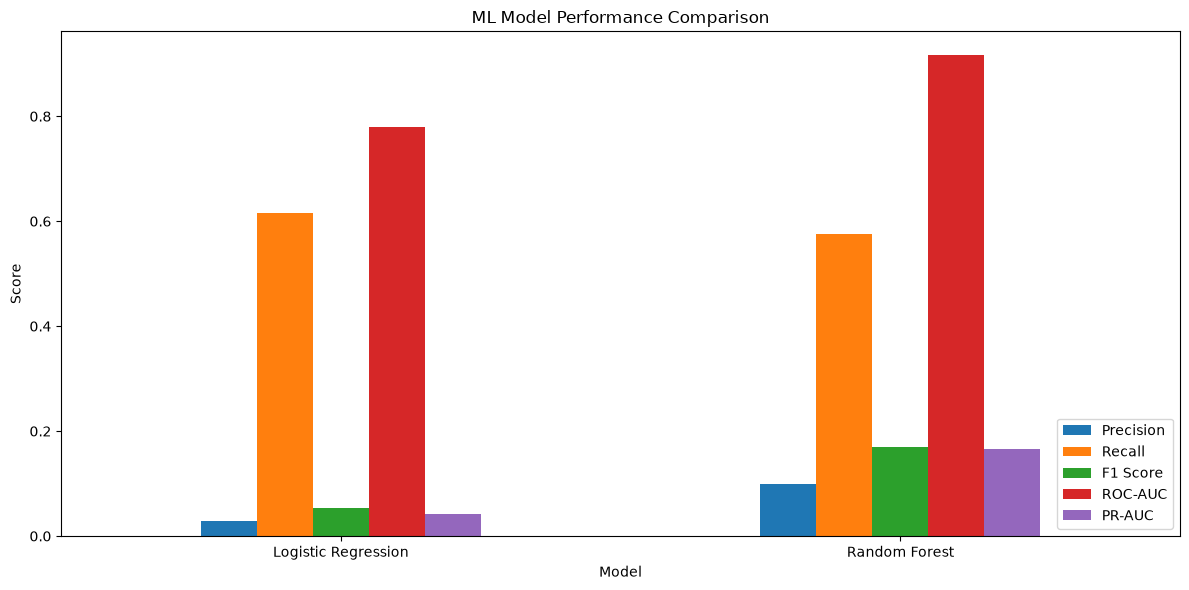

In [92]:
metrics = ['Precision', 'Recall', 'F1 Score', 'ROC-AUC', 'PR-AUC']

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("ML Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

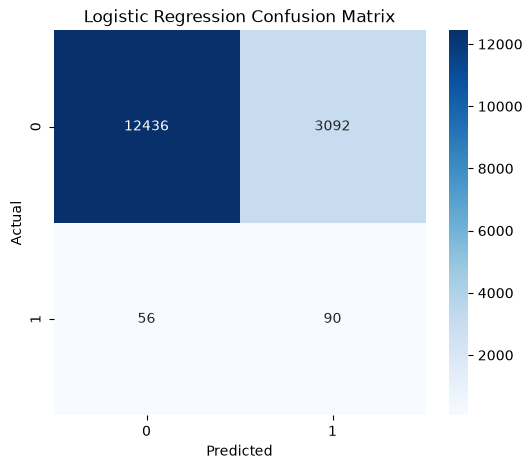

In [93]:
cm_lr = confusion_matrix(
    y_test,
    lr_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

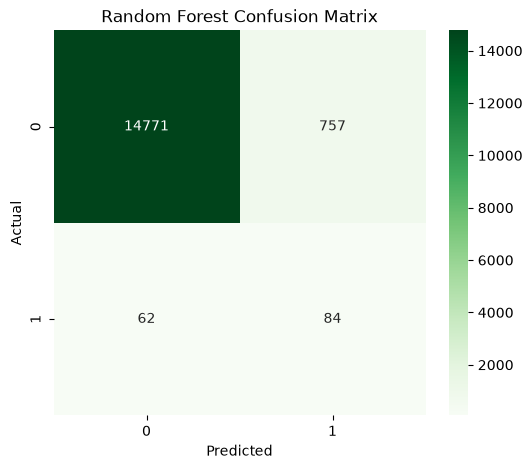

In [94]:
cm_rf = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [95]:
best_model_name = results_df.loc[
    results_df['PR-AUC'].idxmax(),
    'Model'
]

print("BEST MODEL:", best_model_name)

BEST MODEL: Random Forest


In [96]:
results_df.to_csv(
    "../data/processed/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [97]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

print("Optimization libraries imported!")

Optimization libraries imported!


In [98]:
param_grid = {
    'classifier__n_estimators': [100, 150, 200],
    'classifier__max_depth': [10, 15, 20, None],
    'classifier__min_samples_split': [5, 10, 20],
    'classifier__min_samples_leaf': [2, 5, 10],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

In [99]:
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=8,
    scoring='average_precision',
    cv=3,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

print("Randomized Search initialized!")

Randomized Search initialized!


In [100]:
random_search.fit(X_train, y_train)

best_rf_model = random_search.best_estimator_

print("Hyperparameter tuning completed!")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Hyperparameter tuning completed!


In [101]:
print("BEST PARAMETERS")
print("=" * 50)

print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

BEST PARAMETERS
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 15, 'classifier__class_weight': 'balanced'}

Best Cross-Validation PR-AUC:
0.16571351224401756


In [102]:
optimized_predictions = best_rf_model.predict(X_test)

optimized_probabilities = (
    best_rf_model.predict_proba(X_test)[:, 1]
)

print("OPTIMIZED RANDOM FOREST")
print("=" * 50)

print(classification_report(
    y_test,
    optimized_predictions,
    zero_division=0
))

print("ROC-AUC:",
      roc_auc_score(y_test, optimized_probabilities))

print("PR-AUC:",
      average_precision_score(y_test, optimized_probabilities))

OPTIMIZED RANDOM FOREST
              precision    recall  f1-score   support

           0       1.00      0.94      0.97     15528
           1       0.09      0.64      0.16       146

    accuracy                           0.94     15674
   macro avg       0.55      0.79      0.57     15674
weighted avg       0.99      0.94      0.96     15674

ROC-AUC: 0.9159390813237068
PR-AUC: 0.1685057029257771


In [103]:
comparison = pd.DataFrame({
    'Model': [
        'Original Random Forest',
        'Optimized Random Forest'
    ],

    'PR-AUC': [
        average_precision_score(
            y_test, rf_probabilities
        ),
        average_precision_score(
            y_test, optimized_probabilities
        )
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, optimized_probabilities)
    ],

    'F1 Score': [
        f1_score(y_test, rf_predictions),
        f1_score(y_test, optimized_predictions)
    ],

    'Recall': [
        recall_score(y_test, rf_predictions),
        recall_score(y_test, optimized_predictions)
    ]
})

display(comparison.round(4))

,Model,PR-AUC,ROC-AUC,F1 Score,Recall
0,Original Random Forest,0.1663,0.9161,0.1702,0.5753
1,Optimized Random Forest,0.1685,0.9159,0.1633,0.6370


In [104]:
os.makedirs("../data/processed", exist_ok=True)

comparison.to_csv(
    "../data/processed/hyperparameter_comparison.csv",
    index=False
)

print("Optimization results saved!")

Optimization results saved!


In [106]:
%pip install shap
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("SHAP imported successfully!")

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.8 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


SHAP imported successfully!


In [107]:
final_model = best_rf_model

print("Selected Model: Optimized Random Forest")

Selected Model: Optimized Random Forest


In [108]:
preprocessor = final_model.named_steps['preprocessor']

rf_classifier = final_model.named_steps['classifier']

X_sample = X_test.sample(
    n=min(300, len(X_test)),
    random_state=42
)

X_transformed = preprocessor.transform(X_sample)

feature_names = preprocessor.get_feature_names_out()

print("Transformed Shape:", X_transformed.shape)
print("Number of Features:", len(feature_names))

Transformed Shape: (300, 33)
Number of Features: 33


In [109]:
explainer = shap.TreeExplainer(rf_classifier)

shap_values = explainer.shap_values(
    X_transformed
)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


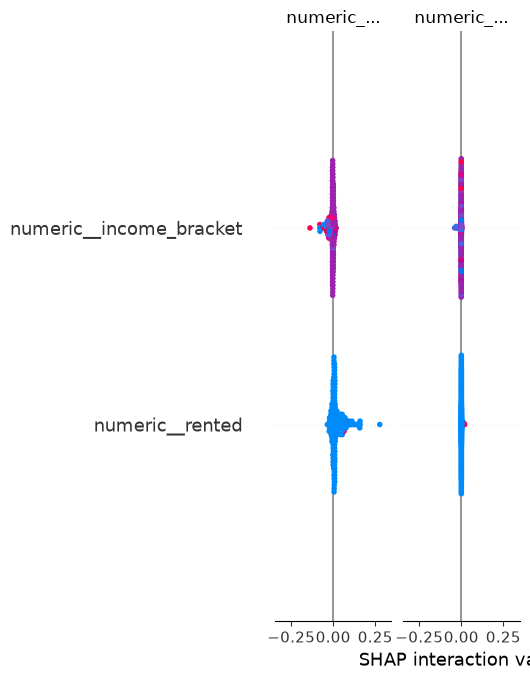

In [110]:
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names,
    show=True
)

In [113]:
importance = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

shap_importance = shap_importance.sort_values(
    by='Importance',
    ascending=False
)

display(shap_importance.head(15))

ValueError: Per-column arrays must each be 1-dimensional

In [114]:
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("SHAP classes:", len(shap_values))

    for i, values in enumerate(shap_values):
        print(f"Class {i} shape:", np.array(values).shape)

else:
    print("SHAP shape:", np.array(shap_values).shape)

print("Feature names:", len(feature_names))

SHAP output type: <class 'numpy.ndarray'>
SHAP shape: (300, 33, 2)
Feature names: 33


In [115]:
# Handle different SHAP output formats

if isinstance(shap_values, list):

    # Select positive class (redemption = 1)
    positive_shap = np.array(shap_values[1])

else:

    shap_array = np.array(shap_values)

    if shap_array.ndim == 3:

        # Select positive class
        positive_shap = shap_array[:, :, 1]

    else:

        positive_shap = shap_array

print("Corrected SHAP Shape:", positive_shap.shape)
print("Feature Count:", len(feature_names))

Corrected SHAP Shape: (300, 33)
Feature Count: 33


In [116]:
importance = np.abs(positive_shap).mean(axis=0)

shap_importance = pd.DataFrame({
    'Feature': list(feature_names),
    'Importance': importance.flatten()
})

shap_importance = shap_importance.sort_values(
    by='Importance',
    ascending=False
)

display(shap_importance.head(15))

,Feature,Importance
10,numeric__total_coupon_discount,0.113197
2,numeric__mapped_item_count,0.090921
11,numeric__total_other_discount,0.035896
7,numeric__total_quantity,0.030492
6,numeric__purchase_frequency,0.029562
8,numeric__total_spending,0.027423
9,numeric__average_spending,0.025629
16,categorical__campaign_type_Y,0.023905
15,categorical__campaign_type_X,0.021166
1,numeric__income_bracket,0.012782


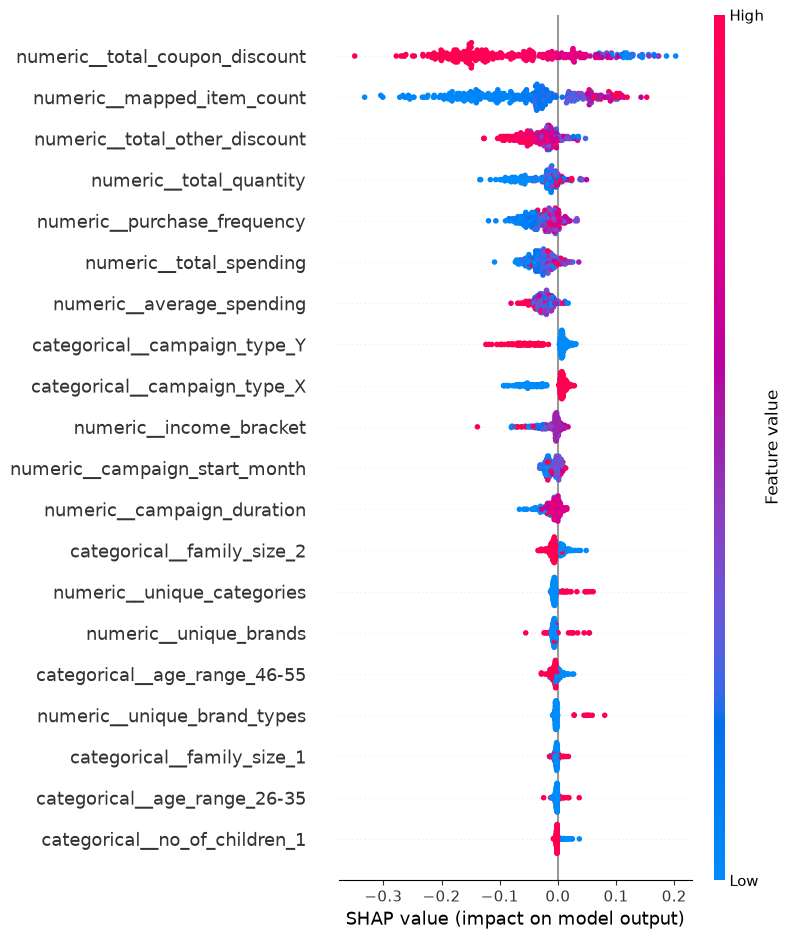

In [117]:
shap.summary_plot(
    positive_shap,
    X_transformed,
    feature_names=feature_names
)

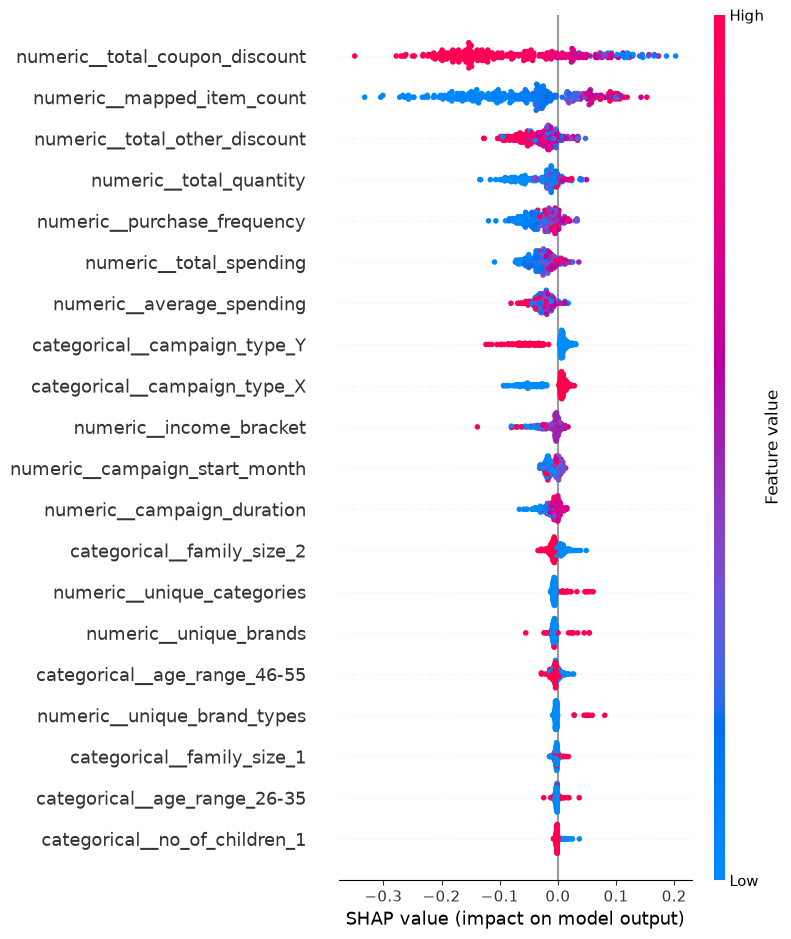

In [118]:
shap.summary_plot(
    positive_shap,
    X_transformed,
    feature_names=feature_names
)

In [119]:
shap_importance.to_csv(
    "../data/processed/shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance saved successfully!")

SHAP feature importance saved successfully!


In [120]:
%pip install joblib streamlit

Note: you may need to restart the kernel to use updated packages.


In [121]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_rf_model,
    "../models/econocausal_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [122]:
feature_info = {
    "features": X_train.columns.tolist(),
    "target": "redemption_status",
    "model": "Random Forest",
    "version": "1.0"
}

joblib.dump(
    feature_info,
    "../models/model_features.pkl"
)

print("Feature information saved!")

Feature information saved!


In [123]:
loaded_model = joblib.load(
    "../models/econocausal_model.pkl"
)

sample_predictions = loaded_model.predict(
    X_test.head(5)
)

print("Sample Predictions:")
print(sample_predictions)

print("\nModel verification successful!")

Sample Predictions:
[1 0 1 0 0]

Model verification successful!


In [124]:
import joblib

model = joblib.load("models/econocausal_model.pkl")

print("Model:", model)

if hasattr(model, "feature_names_in_"):
    print("Expected Features:")
    print(model.feature_names_in_)

FileNotFoundError: [Errno 2] No such file or directory: 'models/econocausal_model.pkl'

In [125]:
import os

print("Current Directory:")
print(os.getcwd())

print("\nModel Files:")
print(os.listdir("../models"))


Current Directory:
C:\Users\KESHAV DEV GAUR\OneDrive\Desktop\EconoCausal\notebooks

Model Files:
['econocausal_model.pkl', 'model_features.pkl']


In [126]:
import joblib

model = joblib.load("../models/econocausal_model.pkl")

print("MODEL LOADED SUCCESSFULLY!")
print("\nModel Details:")
print(model)

if hasattr(model, "feature_names_in_"):
    print("\nExpected Features:")
    print(model.feature_names_in_)

MODEL LOADED SUCCESSFULLY!

Model Details:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['rented', 'income_bracket',
                                                   'mapped_item_count',
                                                   'unique_brands',
                                                   'unique_categories',
                                                   'unique_brand_types',
                                                   'purchase_frequency',
                                                   'total_quantity',
            

In [127]:
features = joblib.load("../models/model_features.pkl")

print("FEATURE INFORMATION:")
print(features)

FEATURE INFORMATION:
{'features': ['campaign_type', 'age_range', 'marital_status', 'rented', 'family_size', 'no_of_children', 'income_bracket', 'mapped_item_count', 'unique_brands', 'unique_categories', 'unique_brand_types', 'purchase_frequency', 'total_quantity', 'total_spending', 'average_spending', 'total_coupon_discount', 'total_other_discount', 'campaign_duration', 'campaign_start_month', 'campaign_start_year'], 'target': 'redemption_status', 'model': 'Random Forest', 'version': '1.0'}
